<a href="https://colab.research.google.com/github/jhormanandrey3-stack/fundamentos-del-curso/blob/main/04_Datos_desde_APIs_y_librerias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04. Datos en línea y primera exploración con Pandas

**Curso:** Análisis de datos para la investigación con Python

**Propósito:** Obtener datos con pocas instrucciones y convertirlos rápidamente en tablas que puedan revisarse, resumirse y graficarse.

**Ruta:** fuente en línea → DataFrame → revisión básica → pregunta exploratoria

Este cuaderno está pensado para una clase virtual demostrativa. Primero se explica la idea, luego se observa el código y, después de varios ejemplos, aparece una pausa práctica.

## Cómo trabajar en Google Colab

1. Guarda una copia del notebook en tu Drive.
2. Ejecuta en orden con el botón de reproducción o con `Shift + Enter`.
3. Una celda de texto explica y una celda de código ejecuta instrucciones.
4. Si reinicias el entorno, usa **Entorno de ejecución → Ejecutar todas**.
5. En las pausas prácticas modifica la celda marcada y luego compara con la solución.

Un error no daña el computador. Lee la última línea del mensaje y revisa nombres, mayúsculas, comillas, paréntesis e indentación.

## 1. La idea esencial

Una API permite solicitar datos a un servicio. Una librería puede simplificar la solicitud. En este curso no construiremos conexiones complejas: descargaremos una tabla, comprobaremos su estructura y empezaremos a explorarla con Pandas.

Trabajaremos con tres ejemplos:

1. Banco Mundial mediante `wbgapi`;
2. datos.gov.co mediante `requests`;
3. Yahoo Finance mediante `yfinance` como muestra breve de otra fuente.
4. scraping de fincaraiz con `Beautifulsuit`

In [ ]:
import sys
import subprocess
import importlib.util

# En Colab instalamos solo las librerías que todavía no están disponibles.
for paquete in ["wbgapi", "yfinance", "bs4", "seaborn", "plotly"]:
    if importlib.util.find_spec(paquete) is None:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q",
            "beautifulsoup4" if paquete == "bs4" else paquete
        ])

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import requests
import wbgapi as wb
import yfinance as yf
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import re
import time

# Definimos el estilo una vez para reutilizarlo en los gráficos del cuaderno.
sns.set_theme(style="whitegrid", palette="crest", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
px.defaults.template = "plotly_white"
print("Entorno preparado")

Entorno preparado


La celda instala únicamente los paquetes que falten. `pandas` administra tablas, `matplotlib` construye gráficos, `requests` consulta una dirección web y las otras dos librerías simplifican fuentes concretas.

## 2. Banco Mundial con una librería

Consultaremos el indicador `IT.NET.USER.ZS`: personas que usan Internet como porcentaje de la población. Solo debemos indicar países y años.

In [ ]:
codigos_paises = ["COL", "MEX", "PER", "CHL", "ARG", "BRA"]

internet_ancho = wb.data.DataFrame(
    "IT.NET.USER.ZS",
    codigos_paises,
    # El límite final de range no se incluye: 2025 permite consultar hasta 2024.
    time=range(2019, 2025),
    labels=True
)
internet_ancho

,Country,YR2019,YR2020,YR2021,YR2022,YR2023,YR2024
economy,,,,,,,
BRA,Brazil,73.912440,81.342694,80.689893,80.527751,84.150602,84.463472
ARG,Argentina,79.946952,85.514386,87.150707,88.375357,89.228972,89.667152
CHL,Chile,85.017601,87.459297,90.232803,92.318199,94.457423,95.590243
PER,Peru,59.950504,65.251798,71.107826,74.674952,79.484845,81.957060
MEX,Mexico,69.632109,71.490175,75.626505,78.632179,81.183188,83.122338
COL,Colombia,65.006901,69.795335,73.028374,72.796379,77.336863,79.345433


Cada fila es un país y cada columna `YR...` es un año. Esta forma ancha sirve para leer una tabla, pero para agrupar y graficar suele ser más cómoda la forma larga: una fila por país-año.

In [ ]:
# El índice contiene los países: lo convertimos en columnas antes de reorganizar.
internet_tabla = internet_ancho.reset_index()
columnas_anio = internet_tabla.filter(like="YR").columns.tolist()

# melt transforma las columnas de años en filas: una observación por país y año.
internet_largo = internet_tabla.melt(
    id_vars=["economy", "Country"],
    value_vars=columnas_anio,
    var_name="anio",
    value_name="internet"
)
# Quitamos el prefijo YR y convertimos el año a número para ordenar y graficar.
internet_largo["anio"] = (
    internet_largo["anio"]
    .str.replace("YR", "", regex=False)
    .astype(int)
)
internet_largo = internet_largo.rename(
    columns={"economy": "codigo_pais", "Country": "pais"}
)
internet_largo.head(15)

,codigo_pais,pais,anio,internet
0,BRA,Brazil,2019,73.912440
1,ARG,Argentina,2019,79.946952
2,CHL,Chile,2019,85.017601
3,PER,Peru,2019,59.950504
4,MEX,Mexico,2019,69.632109
5,COL,Colombia,2019,65.006901
6,BRA,Brazil,2020,81.342694
7,ARG,Argentina,2020,85.514386
8,CHL,Chile,2020,87.459297
9,PER,Peru,2020,65.251798


`melt()` no cambia los valores: reorganiza columnas de años como filas. Ahora `pais` y `anio` identifican una observación y `internet` contiene la medida.

### Pausa práctica: reconocer la tabla

**Tiempo sugerido: 3–5 minutos.** Muestra la forma, los nombres de columnas y los tipos de `internet_largo`.

In [ ]:
# Usa shape, columns y dtypes

### Respuesta sugerida

In [ ]:
print("Forma:", internet_largo.shape)
print("Columnas:", internet_largo.columns.tolist())
print(internet_largo.dtypes)

Forma: (36, 4)
Columnas: ['codigo_pais', 'pais', 'anio', 'internet']
codigo_pais     object
pais            object
anio             int64
internet       float64
dtype: object


In [ ]:
internet_largo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   codigo_pais  36 non-null     object 
 1   pais         36 non-null     object 
 2   anio         36 non-null     int64  
 3   internet     36 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 1.3+ KB


## 3. Primera exploración con Pandas

Antes de una prueba estadística revisamos tamaño, faltantes, rangos y categorías.

In [ ]:
print("Países:", internet_largo["pais"].nunique())
print("Años:", sorted(internet_largo["anio"].unique()))
print("Faltantes:", internet_largo["internet"].isna().sum())

Países: 6
Años: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Faltantes: 0


In [ ]:
internet_largo["internet"].describe().round(2)

,internet
count,36.00
mean,79.99
std,8.58
min,59.95
25%,73.69
50%,80.61
75%,85.92
max,95.59


`describe()` informa cantidad disponible, media, desviación, mínimo, cuartiles y máximo. Todavía no explica por qué existen diferencias.

In [ ]:
resumen_pais = (
    internet_largo
    .groupby("pais")
    .agg(
        promedio_internet=("internet", "mean"),
        minimo_internet=("internet", "min"),
        maximo_internet=("internet", "max")
    )
    .sort_values("promedio_internet", ascending=False)
)
resumen_pais.round(1)

,promedio_internet,minimo_internet,maximo_internet
pais,,,
Chile,90.8,85.0,95.6
Argentina,86.6,79.9,89.7
Brazil,80.8,73.9,84.5
Mexico,76.6,69.6,83.1
Colombia,72.9,65.0,79.3
Peru,72.1,60.0,82.0


Agrupar por país resume seis años. Es distinto de comparar países en un solo año. El periodo debe aparecer en la interpretación.

### Pausa práctica: filtrar una unidad

**Tiempo sugerido: 3–5 minutos.** Selecciona Colombia, ordena por año y calcula el cambio entre primera y última observación.

In [ ]:
# Crea colombia_internet y cambio_colombia

### Respuesta sugerida

In [ ]:
colombia_internet = internet_largo[internet_largo["codigo_pais"].eq("COL")].sort_values("anio")
cambio_colombia = colombia_internet["internet"].iloc[-1] - colombia_internet["internet"].iloc[0]
print(colombia_internet)
print("Cambio:", round(cambio_colombia, 2), "puntos porcentuales")

   codigo_pais      pais  anio   internet
5          COL  Colombia  2019  65.006901
11         COL  Colombia  2020  69.795335
17         COL  Colombia  2021  73.028374
23         COL  Colombia  2022  72.796379
29         COL  Colombia  2023  77.336863
35         COL  Colombia  2024  79.345433
Cambio: 14.34 puntos porcentuales


## 4. Primeras figuras

Un gráfico debe identificar variable, unidad y periodo. Cada línea representa un país; no representa individuos dentro del país.

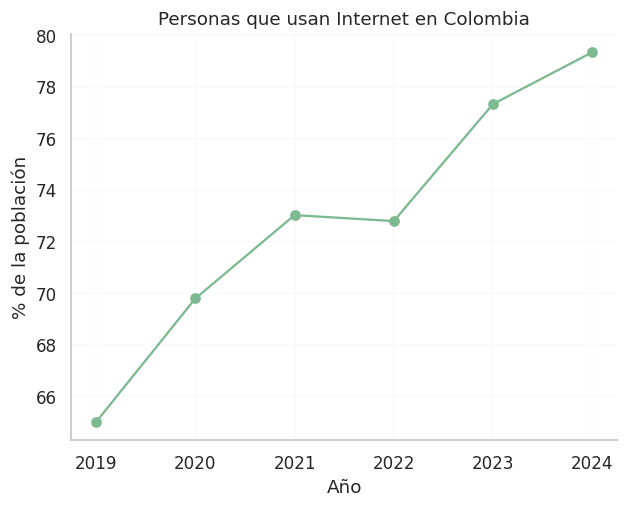

In [ ]:
# Filtramos las observaciones de Colombia y graficamos su evolución en el tiempo.
colombia = internet_largo[
    internet_largo["codigo_pais"] == "COL"
]

plt.plot(
    colombia["anio"],
    colombia["internet"],
    marker="o"
)

plt.title("Personas que usan Internet en Colombia")
plt.xlabel("Año")
plt.ylabel("% de la población")
plt.grid(alpha=0.1)
plt.show()

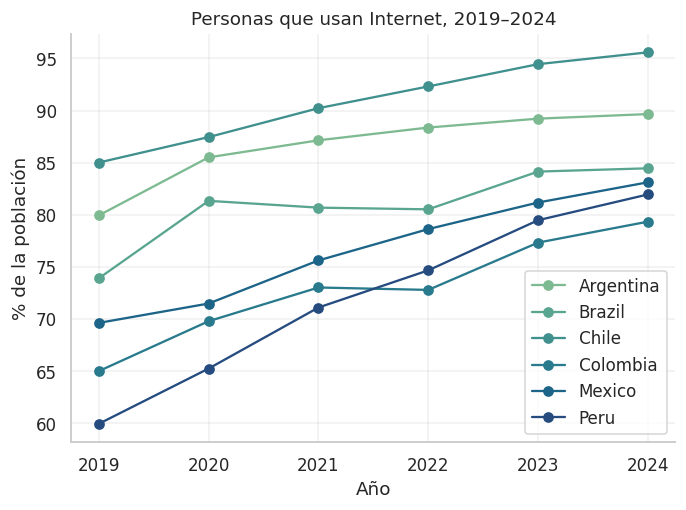

Tiempo de ejecución: 0.2522 segundos


In [ ]:
# Registramos el tiempo de inicio
inicio = time.time()

# Cada grupo reúne las observaciones de un país ordenadas por año.
for codigo, grupo in internet_largo.groupby("codigo_pais"):
    plt.plot(
        grupo["anio"],
        grupo["internet"],
        marker="o",
        label=grupo["pais"].iloc[0]
    )

plt.title("Personas que usan Internet, 2019–2024")
plt.xlabel("Año")
plt.ylabel("% de la población")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculamos y mostramos el tiempo transcurrido
fin = time.time()
tiempo_ejecucion = fin - inicio
print(f"Tiempo de ejecución: {tiempo_ejecucion:.4f} segundos")

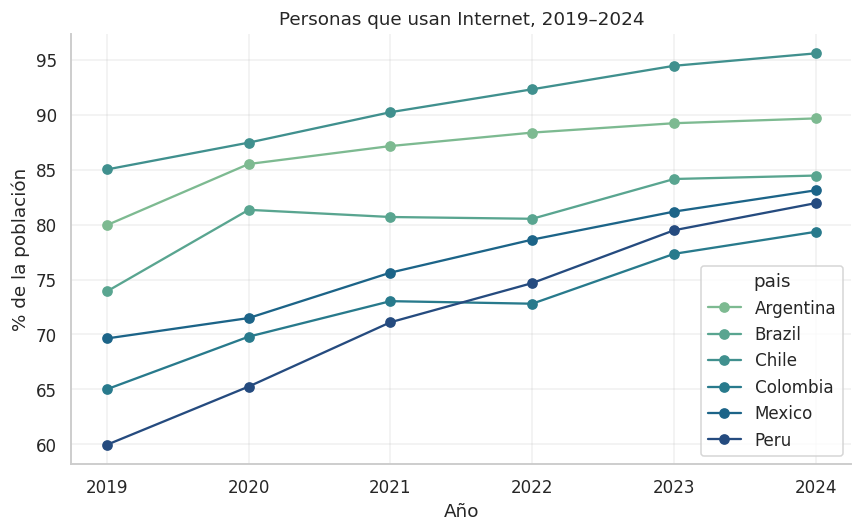

Tiempo de ejecución: 0.2647 segundos


In [ ]:
# Reorganizamos los datos: cada país se convierte en una columna.
# Pandas puede graficar automáticamente una línea por cada columna.

# Registramos el tiempo de inicio
inicio = time.time()

grafico = internet_largo.pivot(
    index="anio",
    columns="pais",
    values="internet"
)

grafico.plot(
    marker="o",
    figsize=(8, 5)
)

plt.title("Personas que usan Internet, 2019–2024")
plt.xlabel("Año")
plt.ylabel("% de la población")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


fin = time.time()
tiempo_ejecucion = fin - inicio
print(f"Tiempo de ejecución: {tiempo_ejecucion:.4f} segundos")

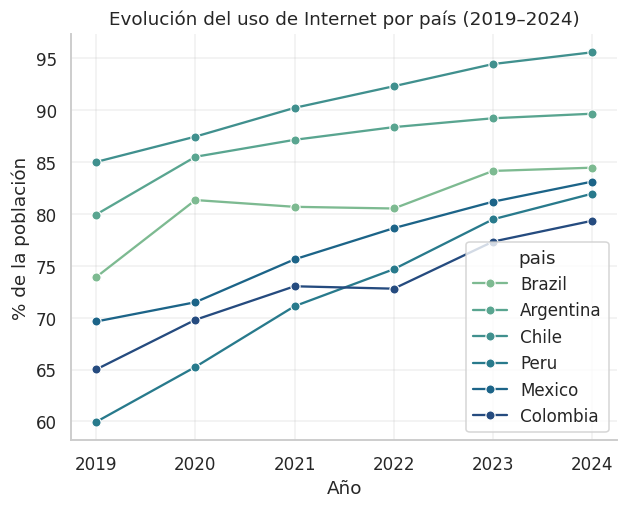

Tiempo de ejecución: 0.2845 segundos


In [ ]:
# Registramos el tiempo de inicio
inicio = time.time()

sns.lineplot(
    data=internet_largo,
    x="anio",
    y="internet",
    hue="pais",
    marker="o"
)
plt.title("Evolución del uso de Internet por país (2019–2024)")
plt.xlabel("Año")
plt.ylabel("% de la población")
plt.grid(alpha=0.3)
plt.show()

fin = time.time()
tiempo_ejecucion = fin - inicio
print(f"Tiempo de ejecución: {tiempo_ejecucion:.4f} segundos")

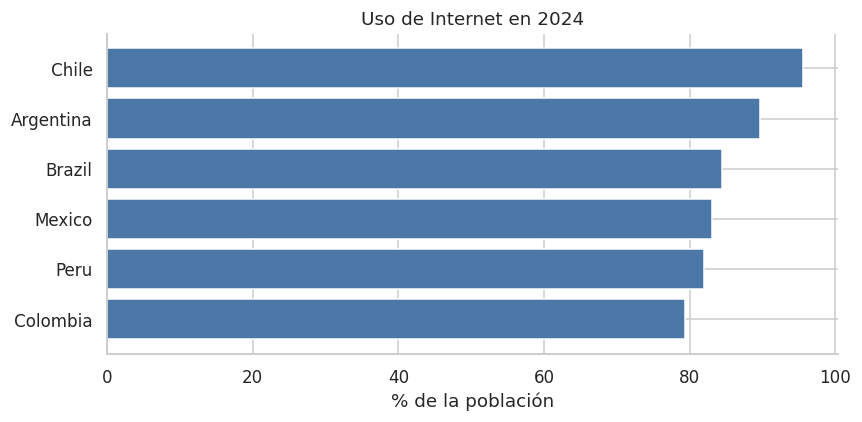

In [ ]:
# Comparamos el mismo año en todos los países; ordenar facilita leer las barras.
internet_2024 = (
    internet_largo[internet_largo["anio"].eq(2024)]
    .sort_values("internet")
)

plt.figure(figsize=(8, 4))
plt.barh(internet_2024["pais"], internet_2024["internet"], color="#4C78A8")
plt.xlabel("% de la población")
plt.title("Uso de Internet en 2024")
plt.tight_layout()
plt.show()

### Pausa práctica: formular una observación

**Tiempo sugerido: 3–5 minutos.** Identifica el valor mayor de 2024 y redacta una frase descriptiva sin lenguaje causal.

In [ ]:
fila_mayor = internet_2024.loc[internet_2024["internet"].idxmax()]
hallazgo = "Completa"
print(fila_mayor)
print(hallazgo)

codigo_pais          CHL
pais               Chile
anio                2024
internet       95.590243
Name: 32, dtype: object
Completa


### Respuesta sugerida

In [ ]:
fila_mayor = internet_2024.loc[internet_2024["internet"].idxmax()]
hallazgo = f"Entre los seis países observados, {fila_mayor['pais']} registró el mayor porcentaje de uso de Internet en 2024 ({fila_mayor['internet']:.1f}%)."
print(hallazgo)

Entre los seis países observados, Chile registró el mayor porcentaje de uso de Internet en 2024 (95.6%).


## 5. Una API directa con `requests`

Para datos.gov.co usamos una dirección y dos parámetros: un filtro y un límite. No desarrollaremos paginación en esta sesión.

In [ ]:
# URL: https://www.datos.gov.co/Vivienda-Ciudad-y-Territorio/Registro-de-transacciones-inmobiliarias-en-Colombi/7y2j-43cv/about_data

# API: https://www.datos.gov.co/api/v3/views/7y2j-43cv/query.json

url_datos_gov = "https://www.datos.gov.co/resource/7y2j-43cv.json"
# Limitamos la descarga y filtramos en el servidor antes de crear la tabla.
parametros = {
    "$limit": 800000,
    "$where": "departamento = 'BOYACÁ'"
}

respuesta = requests.get(url_datos_gov, params=parametros, timeout=40)
print("Código HTTP:", respuesta.status_code)
# Detenemos la celda si la respuesta HTTP indica un error, en lugar de tratarla como datos.
respuesta.raise_for_status()

datos_gov = pd.DataFrame(respuesta.json())
datos_gov.head()

Código HTTP: 200


,pk,matricula,fecha_radica_texto,year_radica,orip,divipola,departamento,municipio,tipo_predio_zona,categoria_ruralidad_2024,...,nombre_natujur,documento_justificativo,count_a,count_de,predios_nuevos,tiene_valor,tiene_mas_de_un_valor,valor,fecha_apertura_texto,folios_derivados
0,15001-070-254569-00001-00920-2023,070-254569,2023-07-18 00:00:00,2023,70,15001,BOYACÁ,TUNJA,URBANO,Ciudades y aglomeraciones,...,LOTEO,00-ESCRITURA 926 DE 22/06/2023; 070-TUNJA,2,0,1,1,0,0.0,NaN,NaN
1,15001-070-254570-00001-00920-2023,070-254570,2023-07-18 00:00:00,2023,70,15001,BOYACÁ,TUNJA,URBANO,Ciudades y aglomeraciones,...,LOTEO,00-ESCRITURA 926 DE 22/06/2023; 070-TUNJA,2,0,1,1,0,0.0,NaN,NaN
2,15001-070-254571-00001-00920-2023,070-254571,2023-07-18 00:00:00,2023,70,15001,BOYACÁ,TUNJA,URBANO,Ciudades y aglomeraciones,...,LOTEO,00-ESCRITURA 926 DE 22/06/2023; 070-TUNJA,2,0,1,1,0,0.0,NaN,NaN
3,15001-070-254572-00001-00920-2023,070-254572,2023-07-18 00:00:00,2023,70,15001,BOYACÁ,TUNJA,URBANO,Ciudades y aglomeraciones,...,LOTEO,00-ESCRITURA 926 DE 22/06/2023; 070-TUNJA,2,0,1,1,0,0.0,NaN,NaN
4,15299-078-034199-00007-00125-2022,078-34199,23/11/22,2022,78,15299,BOYACÁ,GARAGOA,URBANO,Intermedio,...,COMPRAVENTA,00-ESCRITURA 1691 DEL 21/11/22; GARAGOA,1,1,0,1,0,5000000.0,2008-01-24 14:58:45,NaN


El código 200 indica que la solicitud fue atendida. Después convertimos la lista de registros JSON en un DataFrame. La ficha del conjunto sigue siendo necesaria para comprender cada variable.

In [ ]:
print("Forma:", datos_gov.shape)
print("Columnas:", datos_gov.columns.tolist())
print(datos_gov.dtypes.head(10))

Forma: (800000, 24)
Columnas: ['pk', 'matricula', 'fecha_radica_texto', 'year_radica', 'orip', 'divipola', 'departamento', 'municipio', 'tipo_predio_zona', 'categoria_ruralidad_2024', 'num_anotacion', 'estado_folio', 'dinamica_2024', 'cod_natujur', 'nombre_natujur', 'documento_justificativo', 'count_a', 'count_de', 'predios_nuevos', 'tiene_valor', 'tiene_mas_de_un_valor', 'valor', 'fecha_apertura_texto', 'folios_derivados']
pk                          object
matricula                   object
fecha_radica_texto          object
year_radica                 object
orip                        object
divipola                    object
departamento                object
municipio                   object
tipo_predio_zona            object
categoria_ruralidad_2024    object
dtype: object


In [ ]:
if "municipio" in datos_gov.columns:
    print(datos_gov["municipio"].value_counts().head())
else:
    print("El nombre de la columna municipio no aparece en esta respuesta.")

municipio
TUNJA            217023
DUITAMA          112277
CHIQUINQUIRÁ      50764
PAIPA             38561
PUERTO BOYACÁ     24981
Name: count, dtype: int64


### Visualizar la consulta: registros por municipio

Agrupamos los registros descargados y comparamos los diez municipios con más filas. Matplotlib organiza la figura y Seaborn dibuja las barras. El gráfico describe **la consulta limitada a 2.000 registros**, no el total de transacciones de Boyacá; el orden y el límite de descarga afectan lo que vemos.

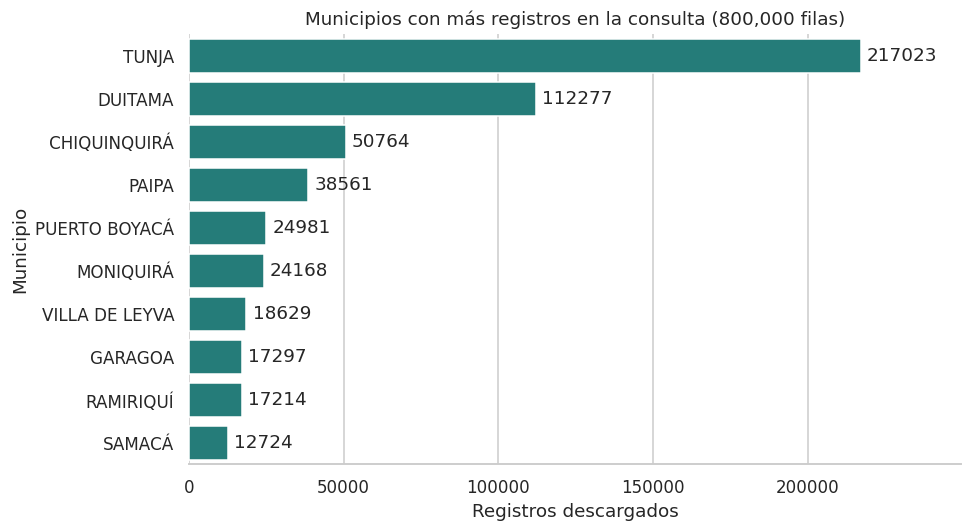

In [ ]:
if "municipio" in datos_gov.columns and not datos_gov.empty:
    # Contamos filas por municipio; no estimamos el total del departamento.
    registros_municipio = (datos_gov["municipio"].dropna().value_counts()
                          .head(10).rename_axis("municipio").reset_index(name="registros"))
    # fig es la figura completa y ax es el espacio donde dibujamos las barras.
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(data=registros_municipio, x="registros", y="municipio",
                color="#168b87", ax=ax)
    # Añadimos los conteos sobre las barras para facilitar la lectura.
    for barra in ax.containers:
        ax.bar_label(barra, padding=4, fmt="%.0f")
    ax.set(title=f"Municipios con más registros en la consulta ({len(datos_gov):,} filas)",
           xlabel="Registros descargados", ylabel="Municipio")
    # Dejamos espacio para las etiquetas y retiramos líneas que no ayudan a comparar.
    ax.margins(x=0.15)
    ax.grid(axis="y", visible=False)
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()
else:
    print("La consulta no contiene registros con la columna municipio para graficar.")

**Para conversar:** ¿por qué el municipio con la barra más larga no necesariamente es el que tiene más transacciones en todo el departamento?

### Pausa práctica: cambiar una consulta

**Tiempo sugerido: 3–5 minutos.** Construye parámetros para solicitar solamente cinco registros de Boyacá. No es necesario repetir la descarga.

In [ ]:
# Crea parametros_cinco

### Respuesta sugerida

In [ ]:
parametros_cinco = {"$limit": 5, "$where": "departamento = 'BOYACÁ'"}
print(parametros_cinco)

{'$limit': 5, '$where': "departamento = 'BOYACÁ'"}


## 6. Yahoo Finance: otra fuente de datos

Yahoo muestra otra estructura: una fila por fecha y columnas por activo. Descargamos los cierres, resumimos sus cambios y comparamos su evolución mediante un gráfico interactivo.

In [ ]:
try:
    # Solicitamos precios ajustados de tres activos como demostración breve.
    precios = yf.download(
        ["AAPL", "MSFT", "SPY"],
        period="3mo",
        auto_adjust=True,
        progress=False,
        threads=False
    )
    # Conservamos el cierre y retiramos fechas incompletas para resumirlo.
    cierres = precios["Close"].dropna()
    print("Forma:", cierres.shape)
    display(cierres.tail())
except Exception as error:
    cierres = pd.DataFrame()
    print("Yahoo Finance no respondió:", type(error).__name__)

Forma: (65, 3)


Ticker,AAPL,MSFT,SPY
Date,,,
2026-10-05,332.890015,525.179993,774.830017
2026-10-06,333.630005,529.299988,779.090027
2026-10-07,336.670013,529.760010,777.219971
2026-10-08,340.420013,522.609985,773.929993
2026-10-09,336.640015,535.070007,778.570007


In [ ]:
if not cierres.empty:
    rendimientos = cierres.pct_change().dropna()
    display(rendimientos.describe().T[["mean", "std", "min", "max"]])
else:
    print("Se omite el resumen porque no hubo descarga.")

,mean,std,min,max
Ticker,,,,
AAPL,0.001176,0.016764,-0.073539,0.040145
MSFT,0.005466,0.024757,-0.030379,0.155067
SPY,0.000544,0.006896,-0.015387,0.018029


`pct_change()` calcula cambios relativos entre fechas consecutivas. Profundizar en estos datos exigiría conceptos de series de tiempo que quedan fuera del alcance.

### Comparar trayectorias con Plotly

Los activos tienen precios distintos. Para comparar sus trayectorias, hacemos que todos comiencen en **100**: dividimos cada cierre por el primero y multiplicamos por 100. Un valor de 110 significa un aumento del 10 % desde el inicio de la serie consultada. Puedes mover el cursor, ampliar un tramo y ocultar un activo desde la leyenda.

In [ ]:
if not cierres.empty:
    # Dividimos cada activo por su primer cierre: así todos parten del mismo valor.
    cierres_base_100 = cierres.div(cierres.iloc[0]).mul(100)
    # Plotly recibe una tabla larga: fecha, nombre del activo y valor del índice.
    trayectorias = (cierres_base_100.rename_axis("fecha").reset_index()
                   .melt(id_vars="fecha", var_name="activo", value_name="indice"))
    fig_precios = px.line(
        trayectorias, x="fecha", y="indice", color="activo",
        title="Evolución de los cierres ajustados · inicio = 100",
        labels={"fecha": "Fecha", "indice": "Índice (inicio = 100)", "activo": "Activo"},
        color_discrete_sequence=["#168b87", "#eb8b38", "#6c5bb6"]
    )
    # La referencia en 100 permite ver aumentos y disminuciones desde el inicio.
    fig_precios.add_hline(y=100, line_dash="dot", line_color="gray")
    # El cursor muestra los tres activos juntos para la misma fecha.
    fig_precios.update_layout(hovermode="x unified", height=430, legend_title_text="Activo")
    fig_precios.show()
else:
    print("No hay cierres descargados para construir el gráfico.")

Estructura de los datos descargados de activos colombianos (ADRs):


Ticker,Bancolombia ADR (NYSE),Ecopetrol ADR (NYSE)
Date,,
2026-10-05,96.059998,17.250000
2026-10-06,96.540001,16.959999
2026-10-07,93.699997,16.629999
2026-10-08,94.080002,16.940001
2026-10-09,94.809998,16.940001


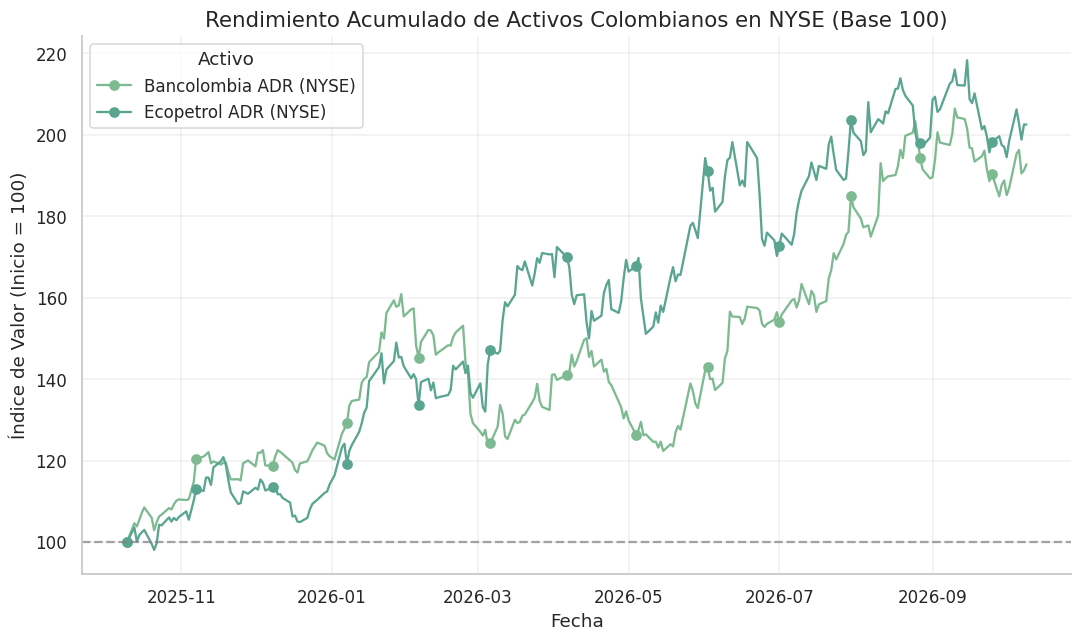

In [ ]:
# Usaremos los ADRs colombianos más líquidos que cotizan en la Bolsa de Nueva York (NYSE)
tickers_bvc_adr = {
    "Bancolombia ADR (NYSE)": "CIB",
    "Ecopetrol ADR (NYSE)": "EC"
}

try:
    # Descargamos los datos históricos del último año de forma segura
    datos_bvc = yf.download(
        list(tickers_bvc_adr.values()),
        period="1y",
        auto_adjust=True,
        progress=False
    )

    # Extraemos los precios de cierre ajustados
    cierres_bvc = datos_bvc["Close"].dropna(how="any")

    # Renombramos las columnas usando los nombres legibles
    tickers_invertidos = {v: k for k, v in tickers_bvc_adr.items()}
    cierres_bvc = cierres_bvc.rename(columns=tickers_invertidos)

    print("Estructura de los datos descargados de activos colombianos (ADRs):")
    display(cierres_bvc.tail())

    # Graficamos la evolución normalizada a base 100 para comparar el rendimiento
    cierres_bvc_100 = cierres_bvc.div(cierres_bvc.iloc[0]).mul(100)

    plt.figure(figsize=(10, 6))
    for columna in cierres_bvc_100.columns:
        plt.plot(cierres_bvc_100.index, cierres_bvc_100[columna], label=columna, marker="o", markevery=20)

    plt.title("Rendimiento Acumulado de Activos Colombianos en NYSE (Base 100)", fontsize=14)
    plt.xlabel("Fecha")
    plt.ylabel("Índice de Valor (Inicio = 100)")
    plt.axhline(y=100, color="gray", linestyle="--", alpha=0.7)
    plt.legend(title="Activo")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Ocurrió un error al consultar los datos: {e}")

**Para conversar:** ¿qué activo termina por encima de su punto de partida y cuál muestra mayores cambios durante el periodo? El gráfico compara el tramo descargado y no predice su comportamiento futuro.

In [ ]:
# Definimos los tickers de las Big Four tecnológicas
tickers = {
    "Apple": "AAPL",
    "Microsoft": "MSFT",
    "Google": "GOOGL",
    "Amazon": "AMZN"
}

resultados = []

for empresa, ticker in tickers.items():
    t_obj = yf.Ticker(ticker)

    try:
        # Estado de resultados (para ingresos)
        incomestmt = t_obj.financials
        # Balance general (para activos y pasivos)
        balance = t_obj.balance_sheet

        # Tomamos el año más reciente disponible en las columnas
        ultimo_anio = balance.columns[0]

        # Si el estado no publica una partida, guardamos None en lugar de inventar cero.
        ingresos = incomestmt.loc['Total Revenue'].iloc[0] if 'Total Revenue' in incomestmt.index else None
        activos = balance.loc['Total Assets'].iloc[0] if 'Total Assets' in balance.index else None
        pasivos = balance.loc['Total Liabilities Net Minority Interest'].iloc[0] if 'Total Liabilities Net Minority Interest' in balance.index else (balance.loc['Total Liabilities'].iloc[0] if 'Total Liabilities' in balance.index else None)

        # Cada empresa aporta un diccionario que después se convierte en una fila.
        resultados.append({
            "Empresa": empresa,
            "Ticker": ticker,
            "Año Fiscal": ultimo_anio.strftime('%Y-%m-%d') if hasattr(ultimo_anio, 'strftime') else ultimo_anio,
            "Ingresos (USD)": ingresos,
            "Activos (USD)": activos,
            "Pasivos (USD)": pasivos
        })
    except Exception as e:
        print(f"No se pudieron obtener todos los datos para {empresa} ({ticker}): {e}")

# Crear DataFrame y dar formato
df_big_four = pd.DataFrame(resultados)
display(df_big_four.round(0))

,Empresa,Ticker,Año Fiscal,Ingresos (USD),Activos (USD),Pasivos (USD)
0,Apple,AAPL,2025-09-30,4.161610e+11,3.592410e+11,2.855080e+11
1,Microsoft,MSFT,2026-06-30,3.318390e+11,7.583760e+11,3.159890e+11
2,Google,GOOGL,2025-12-31,4.028360e+11,5.952810e+11,NaN
3,Amazon,AMZN,2025-12-31,7.169240e+11,8.180420e+11,4.069770e+11


In [ ]:
import pandas as pd
import yfinance as yf

# Obtener el último precio de cierre disponible para AAPL y MSFT
ultimo_precio_aapl = cierres["AAPL"].iloc[-1]
ultimo_precio_msft = cierres["MSFT"].iloc[-1]

per_resultados = []

for ticker, precio in [("AAPL", ultimo_precio_aapl), ("MSFT", ultimo_precio_msft)]:
    t_obj = yf.Ticker(ticker)
    try:
        # Obtenemos el ingreso neto (Net Income) del estado de resultados más reciente
        net_income = t_obj.financials.loc['Net Income'].iloc[0]

        # Obtenemos el número de acciones en circulación desde el balance general
        # Buscamos 'Share Issued' u 'Ordinary Shares Number'
        balance = t_obj.balance_sheet
        shares = None
        for col in ['Ordinary Shares Number', 'Share Issued']:
            if col in balance.index:
                shares = balance.loc[col].iloc[0]
                break

        if net_income and shares:
            # EPS (Beneficio por Acción) = Ingreso Neto / Acciones en circulación
            eps = net_income / shares
            # PER = Precio de Cierre / EPS
            per = precio / eps

            per_resultados.append({
                "Empresa": ticker,
                "Último Precio (USD)": round(precio, 2),
                "Net Income (USD)": f"{net_income:,.0f}",
                "Acciones en Circulación": f"{shares:,.0f}",
                "EPS (USD)": round(eps, 2),
                "PER (P/E Ratio)": round(per, 2)
            })
    except Exception as e:
        print(f"Error al calcular el PER para {ticker}: {e}")

# Mostrar la tabla de resultados
df_per = pd.DataFrame(per_resultados)
display(df_per)

,Empresa,Último Precio (USD),Net Income (USD),Acciones en Circulación,EPS (USD),PER (P/E Ratio)
0,AAPL,336.64,"112,010,000,000","14,773,260,000",7.58,44.40
1,MSFT,535.07,"133,749,000,000","7,427,000,000",18.01,29.71


## 7. Web scraping: ofertas de casas en Tunja

Una API entrega registros estructurados. Una página web entrega HTML: BeautifulSoup permite localizar sus elementos y organizar su contenido.

Consultaremos una página de resultados de Fincaraíz. Extraeremos precio, administración, habitaciones, baños, área y enlace. Son precios de oferta; la tabla no representa ventas realizadas ni todo el mercado.

In [ ]:
url_ofertas = "https://www.fincaraiz.com.co/venta/casas/tunja/boyaca"
respuesta_ofertas = requests.get(url_ofertas, headers={"User-Agent": "Mozilla/5.0"}, timeout=40)
respuesta_ofertas.raise_for_status()
sopa = BeautifulSoup(respuesta_ofertas.text, "html.parser")
anuncios = sopa.select("a.lc-data")
if not anuncios:
    raise ValueError("La respuesta no contiene las tarjetas esperadas. Revisa la página y sus selectores.")
print("Anuncios encontrados:", len(anuncios))

Anuncios encontrados: 21


### Observar una tarjeta

Los selectores identifican elementos del HTML: `p.main-price` busca el precio; `.commonExpenses`, la administración; `.lc-typologyTag__item`, las características. La ausencia de un campo se conserva como dato faltante.

In [ ]:
primero = anuncios[0]
print(primero.get_text(" ", strip=True))
print("Enlace:", urljoin(url_ofertas, primero.get("href", "")))

$ 1.200.000.000 Casa en Tunja, Boyaca 3 Habs. 4 Baños 250 m² Casa en venta en tunja INMOBILIARIA 2 MIL VENDE esta hermosa campestre, con lote de 1.900M2 Aproximadamente y área de construcción 250M2 en un solo nivel.

Sala con chimenea italiana
Comedor
Cocina integral con barra amplia en L, perfecta para cocinar cómodamente en familia
Zona de ropas y depósito
3 habitaciones
4 Baños
Zona central con muro de agua para sala auxiliar
Estudio
Star TV

Excelentes acabados, tanque de reserva, a tan solo 3 minutos de la zona urbana de Combita y a 10 minutos de Tunja.

WHATSAPP. *** Contactar
Enlace: https://www.fincaraiz.com.co/casa-en-venta-en-tunja/192958080


### Extraer texto y convertir números

Separamos las funciones de lectura del recorrido de anuncios. En precios retiramos el símbolo monetario y los separadores de miles. En las características extraemos el número junto a su etiqueta.

In [ ]:
def texto_elemento(anuncio, selector):
    # El selector CSS identifica el texto de una parte del anuncio; puede no existir.
    elemento = anuncio.select_one(selector)
    return elemento.get_text(" ", strip=True) if elemento else None

def valor_pesos(texto):
    if texto is None:
        return None
    # Retiramos el símbolo de moneda y los separadores de miles del precio en pesos.
    digitos = re.sub(r"[^0-9]", "", texto)
    return int(digitos) if digitos else None

def caracteristica(anuncio, etiqueta):
    # Buscamos la etiqueta (habitaciones, baños o área) antes de extraer su número.
    for elemento in anuncio.select(".lc-typologyTag__item"):
        texto = elemento.get_text(" ", strip=True)
        if etiqueta in texto:
            coincidencia = re.search(r"[0-9]+(?:[.,][0-9]+)?", texto)
            if coincidencia:
                # Normalizamos la coma decimal para que Python pueda convertir el texto.
                return float(coincidencia.group().replace(",", "."))
    return None

In [ ]:
filas_ofertas = []
# Repetimos las mismas reglas en cada tarjeta para formar filas con columnas comunes.
for anuncio in anuncios:
    filas_ofertas.append({
        "titulo": texto_elemento(anuncio, ".lc-title"),
        "ubicacion": texto_elemento(anuncio, ".lc-location"),
        "precio_cop": valor_pesos(texto_elemento(anuncio, ".main-price")),
        "administracion_cop": valor_pesos(texto_elemento(anuncio, ".commonExpenses")),
        "habitaciones": caracteristica(anuncio, "Habs"),
        "banos": caracteristica(anuncio, "Baños"),
        "area_m2": caracteristica(anuncio, "m²"),
        "enlace": urljoin(url_ofertas, anuncio.get("href", "")),
    })

# El enlace identifica la oferta: evitamos contar dos veces una tarjeta repetida.
ofertas = pd.DataFrame(filas_ofertas).drop_duplicates(subset="enlace").reset_index(drop=True)
columnas_numericas = ["precio_cop", "administracion_cop", "habitaciones", "banos", "area_m2"]
# errors="coerce" conserva los valores no interpretables como faltantes, no como ceros.
for columna in columnas_numericas:
    ofertas[columna] = pd.to_numeric(ofertas[columna], errors="coerce")
ofertas

,titulo,ubicacion,precio_cop,administracion_cop,habitaciones,banos,area_m2,enlace
0,Casa en venta en tunja,"Casa en Tunja, Boyaca",1200000000,NaN,3.0,4.0,250.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
1,"Casa en venta en las nieves, tunja","Casa en Tunja, Boyaca",500000000,NaN,6.0,4.0,180.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
2,"Casa en venta en las nieves, tunja","Casa en Tunja, Boyaca",680000000,NaN,6.0,4.0,185.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
3,Casa en venta en tunja,"Casa en Tunja, Boyaca",280000000,NaN,5.0,4.0,120.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
4,Casa en venta en san jose,"Casa en Tunja, Boyaca",500000000,NaN,3.0,4.0,94.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
5,Casa en venta en tunja,"Casa en Tunja, Boyaca",680000000,NaN,5.0,4.0,235.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
6,Casa en venta en tunja,"Casa en Tunja, Boyaca",490000000,75000.0,4.0,3.0,157.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
7,"Casa en venta en surinama, tunja","Casa en Tunja, Boyaca",350000000,NaN,4.0,3.0,150.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
8,"Casa en venta en altagracia, tunja","Casa en Tunja, Boyaca",675000000,260000.0,NaN,NaN,114.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
9,Casa en venta en tunja,"Casa en Tunja, Boyaca",650000000,NaN,3.0,3.0,147.0,https://www.fincaraiz.com.co/casa-en-venta-en-...


### Revisar y analizar la tabla

Calculamos precio por metro cuadrado cuando el área es positiva. Administración sin valor no significa administración igual a cero. El área corresponde al campo publicado y debe interpretarse según el anuncio.

In [ ]:
display(ofertas[columnas_numericas].isna().sum())
ofertas["precio_m2_cop"] = ofertas["precio_cop"] / ofertas["area_m2"].where(ofertas["area_m2"] > 0)
display(ofertas[["titulo", "precio_cop", "area_m2", "precio_m2_cop"]].sort_values("precio_m2_cop").round(0))

,0
precio_cop,0
administracion_cop,15
habitaciones,1
banos,1
area_m2,0


,titulo,precio_cop,area_m2,precio_m2_cop
14,"Casa en venta en la maria, tunja",545000000,290.0,1879310.0
16,"Casa en venta en la maria, tunja",500000000,262.0,1908397.0
15,Casa en venta en tunja,280000000,125.0,2240000.0
3,Casa en venta en tunja,280000000,120.0,2333333.0
7,"Casa en venta en surinama, tunja",350000000,150.0,2333333.0
10,Casa en venta en tunja,500000000,210.0,2380952.0
18,Casa en venta en tunja,370000000,137.0,2700730.0
1,"Casa en venta en las nieves, tunja",500000000,180.0,2777778.0
20,Casa en venta en tunja,750000000,268.0,2798507.0
5,Casa en venta en tunja,680000000,235.0,2893617.0


### Visualizar las ofertas: área, precio y precio por m²

El diagrama de dispersión muestra una oferta por punto: relaciona el área publicada con el precio y usa el color para distinguir habitaciones. El histograma resume el precio por m². Retiramos de estos gráficos las filas sin precio o área positivos, sin modificar la tabla original.

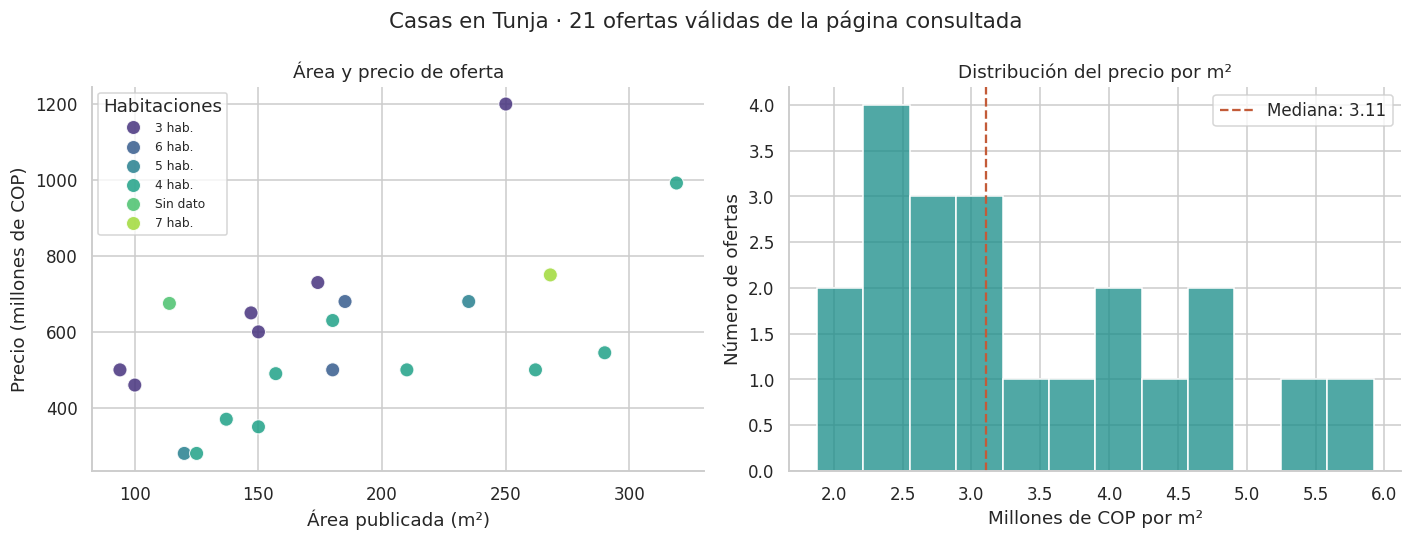

In [ ]:
# Trabajamos sobre una copia; precio y área deben ser positivos para calcular precio por m².
ofertas_grafico = ofertas.loc[(ofertas["precio_cop"] > 0) & (ofertas["area_m2"] > 0)].copy()
# Expresamos pesos en millones para que las escalas sean más legibles.
ofertas_grafico["precio_millones"] = ofertas_grafico["precio_cop"] / 1_000_000
ofertas_grafico["precio_m2_millones"] = ofertas_grafico["precio_m2_cop"] / 1_000_000
# Tratamos las habitaciones como categorías y hacemos visibles los anuncios sin dato.
ofertas_grafico["grupo_habitaciones"] = ofertas_grafico["habitaciones"].apply(
    lambda valor: "Sin dato" if pd.isna(valor) else f"{valor:g} hab."
)

if not ofertas_grafico.empty:
    # Creamos dos espacios: ejes[0] para la dispersión y ejes[1] para la distribución.
    fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
    sns.scatterplot(data=ofertas_grafico, x="area_m2", y="precio_millones",
                    hue="grupo_habitaciones", palette="viridis", s=85,
                    alpha=0.85, edgecolor="white", ax=ejes[0])
    ejes[0].set(title="Área y precio de oferta", xlabel="Área publicada (m²)",
                ylabel="Precio (millones de COP)")
    ejes[0].legend(title="Habitaciones", fontsize=8)
    # Las barras cuentan ofertas dentro de cada intervalo de precio por m².
    sns.histplot(data=ofertas_grafico, x="precio_m2_millones", bins=12,
                 color="#168b87", edgecolor="white", ax=ejes[1])
    # La mediana sirve como referencia central sin ocultar la dispersión de precios.
    mediana_m2 = ofertas_grafico["precio_m2_millones"].median()
    ejes[1].axvline(mediana_m2, color="#c35b38", linestyle="--",
                   label=f"Mediana: {mediana_m2:.2f}")
    ejes[1].set(title="Distribución del precio por m²", xlabel="Millones de COP por m²",
                ylabel="Número de ofertas")
    ejes[1].legend()
    fig.suptitle(f"Casas en Tunja · {len(ofertas_grafico)} ofertas válidas de la página consultada", fontsize=14)
    sns.despine()
    plt.tight_layout()
    plt.show()
else:
    print("No hay ofertas con precio y área positivos para graficar.")

**Para conversar:** identifica una oferta que se aparte del grupo y revisa su anuncio antes de interpretarla. Los gráficos muestran precios publicados en una página de resultados; no representan precios de cierre ni una muestra representativa del mercado.

### Pausa práctica: seleccionar ofertas

Selecciona ofertas con precio menor o igual a 400 millones y área mayor o igual a 100 m². Ordena por precio y muestra precio, área y enlace.

In [ ]:
# Desarrolla el ejercicio aquí.

### Respuesta sugerida

In [ ]:
seleccion_ofertas = ofertas.loc[(ofertas["precio_cop"] <= 400_000_000) & (ofertas["area_m2"] >= 100), ["precio_cop", "area_m2", "enlace"]].sort_values("precio_cop")
seleccion_ofertas

,precio_cop,area_m2,enlace
3,280000000,120.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
15,280000000,125.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
7,350000000,150.0,https://www.fincaraiz.com.co/casa-en-venta-en-...
18,370000000,137.0,https://www.fincaraiz.com.co/casa-en-venta-en-...


In [ ]:
ofertas.to_csv("ofertas_casas_tunja.csv", index=False, encoding="utf-8-sig")
print("Filas exportadas:", len(ofertas))

Filas exportadas: 21


## 8. Puente hacia el EDA

Ya podemos hacer cuatro preguntas iniciales sobre una tabla descargada:

1. ¿cuántas filas, columnas y unidades contiene?;
2. ¿qué tipos y valores faltantes aparecen?;
3. ¿cuáles son los rangos y grupos principales?;
4. ¿qué patrón merece una exploración más profunda?

El notebook 5 desarrolla distribuciones, atípicos, correlaciones e hipótesis.

In [ ]:
ficha_consulta = {
    "fuente": "Banco Mundial",
    "indicador": "IT.NET.USER.ZS",
    "periodo": "2019-2024",
    "unidad_analisis": "país-año",
    "unidad_medida": "% de la población",
}
print(ficha_consulta)

{'fuente': 'Banco Mundial', 'indicador': 'IT.NET.USER.ZS', 'periodo': '2019-2024', 'unidad_analisis': 'país-año', 'unidad_medida': '% de la población'}


## Cierre

El propósito no fue dominar protocolos de API, sino comprobar que una fuente en línea termina en un DataFrame y que desde allí aplicamos la misma lógica de Pandas: observar, tipar, filtrar, agrupar, resumir y graficar.